# Introduction to Machine Learning – Lab 2
## Hyperparameter Tuning and Bayesian Optimization with Optuna

### Objective
Notebook 02 showed that the default XGBoost model has a **high variance**: it fits every training house perfectly (training macro-F1 1.0), but reaches only about 0.75 macro-F1 on new houses. Notebook 04 showed that changing the data preparation does not close this gap. This notebook therefore changes the model itself:
1. **Manual tuning:** one hyperparameter at a time is changed while all others keep their default value, to see how each one moves the training score, the test score and the gap between them (bias-variance tradeoff).
2. **Bayesian optimization with Optuna:** the `TPESampler` searches all hyperparameters together for the best macro-F1. All trials are stored in an SQLite database, so an interrupted search can be resumed.
3. **Visualizations of the optimization process:** how the search progressed and which hyperparameters mattered.
4. **Final model:** the tuned models are compared with the baseline on all evaluation setups of notebook 02, and the diagnostics of notebook 03 are repeated for the best one.

**Data and protocol:** same data and encoding as notebooks 02–04 (2,925 houses, 72 features, one-hot encoding). Tuning uses the 5 folds of the stratified 5-fold cross-validation (`CV k=5, stratified`) of notebooks 02–04, with macro-F1 as the main metric.

In [1]:
import sys
import warnings
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from optuna.pruners import MedianPruner
from optuna.samplers import TPESampler
from optuna.visualization import matplotlib as optuna_plots
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold

from evaluation import evaluate, make_splits, paired_differences, summarize
from preprocessing import CLASS_NAMES, build_pipeline, prepare_data

sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)
# The matplotlib versions of the Optuna plots are marked as experimental
warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

# Same data as notebooks 02–04
X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
print(f"Dataset dimensions: X = {X.shape}, y = {y.shape}")

# All 70 splits of notebooks 02 and 04 (final comparison), and the 5 folds used for tuning
splits = make_splits(y)
cv5 = [split for split in splits if split["Setup"] == "CV k=5, stratified"]

# Default values of the studied hyperparameters in XGBoost: this is the baseline model of notebook 02
DEFAULTS = {
    "max_depth": 6,
    "learning_rate": 0.3,
    "n_estimators": 100,
    "min_child_weight": 1,
    "subsample": 1.0,
    "colsample_bytree": 1.0,
    "reg_lambda": 1.0,
    "reg_alpha": 0.0,
    "gamma": 0.0,
}
METRICS = ["Train Macro-F1", "Test Macro-F1", "Test Macro-F1 Std", "Test Accuracy", "Gap"]


def make_model(**params):
    """Baseline pipeline of notebook 02 (one-hot + XGBoost) with some hyperparameters changed."""
    return build_pipeline(
        "onehot", min_frequency=5, enable_categorical=False, tree_method="hist", **{**DEFAULTS, **params}
    )


def cv_scores(model):
    """Mean scores over the 5 stratified folds; Gap = training minus test macro-F1 (variance)."""
    scores = evaluate(model, X, y, cv5)
    return {
        "Train Macro-F1": scores["Train Macro-F1"].mean(),
        "Test Macro-F1": scores["Test Macro-F1"].mean(),
        # Sample standard deviation over the folds, as in notebook 04
        "Test Macro-F1 Std": scores["Test Macro-F1"].std(),
        "Test Accuracy": scores["Test Accuracy"].mean(),
        "Gap": scores["Train Macro-F1"].mean() - scores["Test Macro-F1"].mean(),
    }


baseline_scores = cv_scores(make_model())
print("Baseline (default hyperparameters), 5-fold stratified CV:")
display(pd.DataFrame([baseline_scores]).round(4))

Dataset dimensions: X = (2925, 72), y = (2925,)


Baseline (default hyperparameters), 5-fold stratified CV:


,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,1.0,0.7494,0.0236,0.7641,0.2506


The baseline matches notebooks 02 and 04 on the same folds: training macro-F1 1.0, test macro-F1 0.7494 ± 0.0236, test accuracy 0.7641, gap 0.2506. In every experiment below, the row with the default value has exactly these scores.

### 1. Manual hyperparameter tuning

#### What the hyperparameters do
XGBoost adds one tree per class in every boosting round. For a leaf with the summed gradients $G$ and hessians $H$ of its training houses, the best leaf value and the gain of a split into a left part $L$ and a right part $R$ are

$$w^* = -\frac{G}{H + \lambda}, \qquad \text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma$$

and the prediction is updated by $\eta \cdot w^*$ in every round. Most hyperparameters act on these quantities:

| Hyperparameter | Default | What it controls | More regularization means |
|---|---|---|---|
| `max_depth` | 6 | Maximum depth of each tree, i.e. how many features one tree can combine | Smaller value: simpler trees |
| `learning_rate` ($\eta$) | 0.3 | Factor by which every tree's prediction is shrunk | Smaller value: smaller steps, needs more rounds |
| `n_estimators` | 100 | Number of boosting rounds | Fewer rounds (at a fixed learning rate) |
| `min_child_weight` | 1 | Minimum sum of hessians $H$ (cover) in a leaf | Larger value: no leaves for a handful of houses |
| `subsample` | 1.0 | Share of the training houses drawn (without replacement) for each tree | Smaller value: each tree sees different houses |
| `colsample_bytree` | 1.0 | Share of the features drawn for each tree | Smaller value: each tree uses different features |
| `reg_lambda` ($\lambda$) | 1 | L2 penalty: enlarges the denominator of $w^*$ and of the gain | Larger value: smaller leaf values, fewer splits on few houses |
| `reg_alpha` ($\alpha$) | 0 | L1 penalty: shrinks $G$ towards 0 before $w^*$ is computed | Larger value: small leaf values become exactly 0 |
| `gamma` ($\gamma$) | 0 | Minimum gain a split must reach | Larger value: weak splits are not made (pruning) |

More regularization lowers the **variance** (the model fits less noise of the training houses) but raises the **bias** (the model may miss real patterns). Since the default model has a training macro-F1 of 1.0 and a gap of about 0.25 (notebook 02), the main question is how much each hyperparameter can reduce the gap without making the test score worse.

#### Protocol
* **One at a time:** in each experiment, one hyperparameter (or the pair `learning_rate`/`n_estimators`, which only make sense together) is changed, all others keep their default value. The row with the default value is the baseline.
* **Same folds:** every configuration is fitted and scored on the same 5 stratified folds, so differences between rows never come from different test houses.
* **Reported scores:** mean training macro-F1 (on the training folds), mean test macro-F1 ± standard deviation over the 5 folds, mean test accuracy, and the gap = training macro-F1 − test macro-F1.
* **Noise level:** in notebook 04, differences below about 0.01 macro-F1 were within the spread between splits, so only larger differences are treated as real effects here.

In [2]:
def sweep(values, param=None):
    """Score one configuration per value; all hyperparameters that are not changed keep their default."""
    rows = []
    for value in values:
        # A dict changes several hyperparameters at once (e.g. learning_rate and n_estimators)
        params = value if isinstance(value, dict) else {param: value}
        rows.append({**params, **cv_scores(make_model(**params))})
    return pd.DataFrame(rows)

#### 1.1 Tree depth (`max_depth`)
The depth limits how many splits lie on the path from the root to a leaf, i.e. how many features one tree can combine. The default is 6 (up to 64 leaves per tree).

In [3]:
# Shallow trees (2–4) are strongly regularized; 8 and 10 allow more interactions than the default 6
sweep_depth = sweep([2, 3, 4, 6, 8, 10], "max_depth")
display(sweep_depth.round(4))

,max_depth,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,2,0.9305,0.7490,0.0119,0.7655,0.1816
1,3,0.9874,0.7483,0.0186,0.7631,0.2391
2,4,0.9995,0.7477,0.0317,0.7634,0.2519
3,6,1.0000,0.7494,0.0236,0.7641,0.2506
4,8,1.0000,0.7437,0.0292,0.7631,0.2563
5,10,1.0000,0.7388,0.0208,0.7556,0.2612


**Result:**
* Shallower trees fit the training houses less: the training macro-F1 is 0.9305 at depth 2 and 0.9874 at depth 3, and from depth 4 on it is (practically) 1.0. The gap shrinks from 0.2506 (depth 6) to 0.1816 (depth 2).
* The test macro-F1 does not follow: 0.7490 (depth 2), 0.7483 (3) and 0.7477 (4) vs. 0.7494 (6), all within 0.002. Deeper trees are slightly worse: 0.7437 (8) and 0.7388 (10), with gaps of 0.2563 and 0.2612.

**Explanation:** shallower trees lower the variance, but they raise the bias by about the same amount. A depth-2 tree can only combine two features (e.g. quality and size), and more rounds cannot fully make up for that. The smaller gap at depth 2 comes from the lower training score, not from a higher test score. One side effect is visible, though: depth 2 has the smallest spread over the folds (± 0.0119 vs. ± 0.0236), so its score depends least on which houses are in the training folds. Deeper trees (8, 10) add interactions that only describe single training houses (more variance) and lose 0.006–0.011.

#### 1.2 Learning rate and number of rounds (`learning_rate`, `n_estimators`)
The learning rate shrinks every tree, so a smaller rate needs more rounds to reach the same training fit. The two are therefore changed together: the default (0.3, 100 rounds), more rounds at the default rate, a smaller rate with the default number of rounds, and smaller rates with proportionally more rounds.

In [4]:
# learning_rate × n_estimators = 30 for the default, the two "slow" settings keep a similar product
sweep_rate = sweep([
    {"learning_rate": 0.3, "n_estimators": 100},   # default
    {"learning_rate": 0.3, "n_estimators": 300},   # more rounds at the default rate
    {"learning_rate": 0.1, "n_estimators": 100},   # smaller rate, same number of rounds
    {"learning_rate": 0.1, "n_estimators": 300},   # smaller rate, 3x the rounds
    {"learning_rate": 0.05, "n_estimators": 600},  # even smaller rate, 6x the rounds
])
display(sweep_rate.round(4))

,learning_rate,n_estimators,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,0.30,100,1.000,0.7494,0.0236,0.7641,0.2506
1,0.30,300,1.000,0.7454,0.0274,0.7634,0.2546
2,0.10,100,0.998,0.7260,0.0310,0.7491,0.2720
3,0.10,300,1.000,0.7399,0.0327,0.7621,0.2601
4,0.05,600,1.000,0.7479,0.0309,0.7679,0.2521


**Result:**
* At the default learning rate, 300 instead of 100 rounds change little (0.7454 vs. 0.7494): the training macro-F1 is already 1.0 after 100 rounds, so the extra rounds only fit the training houses more closely.
* A smaller learning rate with the same 100 rounds is clearly worse: 0.7260 (−0.023), the largest loss in this experiment. With 300 rounds at 0.1, most of it is recovered (0.7399), and 0.05 with 600 rounds is back at the default level (0.7479), with the highest accuracy of this experiment (0.7679).

**Explanation:** each round moves the prediction by $\eta \cdot w^*$, so the learning rate and the number of rounds act together, roughly through their product. The three settings with learning rate × rounds = 30 lie within 0.01 of each other (0.7494, 0.7399, 0.7479). With a product of only 10 (0.1 × 100), the training houses are already classified almost perfectly (0.998), but the test score is 0.023 lower. The training score cannot show this kind of underfitting, only the test score does. A smaller learning rate alone does not reduce the gap either (0.2521 at 0.05 / 600): with enough rounds, the model memorizes the training houses just as well. It pays off only together with other regularization (Section 2).

#### 1.3 Minimum leaf weight (`min_child_weight`)
A split is only made if each side keeps a hessian sum (cover) of at least `min_child_weight`. For the softmax loss, XGBoost uses the hessian $2p(1-p)$ per house, at most 0.5, so a value of 5 requires at least 10 houses in a leaf, and more in later rounds, when the model is confident about many houses ($p$ close to 0 or 1).

In [5]:
# Larger values forbid leaves that describe only a handful of houses
sweep_mcw = sweep([1, 3, 5, 10, 20], "min_child_weight")
display(sweep_mcw.round(4))

,min_child_weight,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,1,1.0000,0.7494,0.0236,0.7641,0.2506
1,3,1.0000,0.7519,0.0330,0.7668,0.2481
2,5,1.0000,0.7456,0.0316,0.7634,0.2544
3,10,0.9987,0.7432,0.0294,0.7644,0.2555
4,20,0.9799,0.7327,0.0195,0.7518,0.2472


**Result:**
* Up to 10, the training macro-F1 stays at (almost) 1.0 (0.9987 at 10). Only at 20 does it drop, to 0.9799.
* The test macro-F1 is highest at 3 (0.7519, +0.0025, within the noise) and falls for larger values: 0.7456 (5), 0.7432 (10), 0.7327 (20).

**Explanation:** the gap stays between 0.247 and 0.256 for all values, so forbidding small leaves does not stop the memorizing: over 100 rounds, every training house can still be fitted in leaves it shares with other houses. Larger values most likely hurt the test score because they hit the rare classes first. A training fold contains only about 50 houses ≥ \$400k, and leaves that separate a small group of them are no longer allowed.

#### 1.4 Row and column subsampling (`subsample`, `colsample_bytree`)
With `subsample` < 1, every tree is fitted on a random share of the training houses (stochastic gradient boosting). With `colsample_bytree` < 1, every tree may only use a random share of the features. Both make consecutive trees less similar, similar to the random sampling in a random forest.

In [6]:
# Each tree is fitted on 100%, 80%, 60% or 40% of the training houses
sweep_subsample = sweep([1.0, 0.8, 0.6, 0.4], "subsample")
display(sweep_subsample.round(4))

# Each tree may use 100%, 80%, 50% or 30% of the 200 encoded features
sweep_colsample = sweep([1.0, 0.8, 0.5, 0.3], "colsample_bytree")
display(sweep_colsample.round(4))

,subsample,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,1.0,1.0,0.7494,0.0236,0.7641,0.2506
1,0.8,1.0,0.7493,0.0321,0.7621,0.2507
2,0.6,1.0,0.7489,0.0308,0.7648,0.2511
3,0.4,1.0,0.7404,0.0262,0.7614,0.2596


,colsample_bytree,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,1.0,1.0,0.7494,0.0236,0.7641,0.2506
1,0.8,1.0,0.7520,0.0256,0.7668,0.2480
2,0.5,1.0,0.7458,0.0231,0.7679,0.2542
3,0.3,1.0,0.7375,0.0282,0.7603,0.2625


**Result:**
* `subsample`: the training macro-F1 stays 1.0 for all values. The test macro-F1 is the same as the default at 0.8 and 0.6 (0.7493, 0.7489) and lower at 0.4 (0.7404, −0.009).
* `colsample_bytree`: the training macro-F1 also stays 1.0. The test macro-F1 is 0.7520 at 0.8 (+0.0026, within the noise), 0.7458 at 0.5 and 0.7375 at 0.3 (−0.012). At 0.5, the accuracy is the highest of both experiments (0.7679) although the macro-F1 drops. Accuracy is dominated by the large classes and macro-F1 weights all classes equally, so the large classes gain while at least one small class loses.

**Explanation:** sampling makes consecutive trees less similar. But at a learning rate of 0.3, every tree has a large weight, and 100 trees are enough to memorize the training houses anyway. The training score never drops below 1.0, so the variance is not reduced. Strong sampling (40% of the houses, 30% of the features) makes every single tree worse (more bias). Random sampling works best together with a small learning rate, where many trees average out the randomness. Section 2 shows exactly this combination.

#### 1.5 Penalties on the leaf values (`reg_lambda`, `reg_alpha`)
$\lambda$ (L2) is added to the hessian sum in the leaf value and the gain, so it shrinks all leaf values and makes splits that isolate few houses (small $H$) less attractive. $\alpha$ (L1) subtracts a fixed amount from $|G|$, so leaves with a weak signal get the value 0.

In [7]:
# L2 penalty: default 1; 0 switches it off
sweep_lambda = sweep([0.0, 1.0, 5.0, 20.0, 50.0], "reg_lambda")
display(sweep_lambda.round(4))

# L1 penalty: default 0 (off)
sweep_alpha = sweep([0.0, 0.5, 2.0, 5.0], "reg_alpha")
display(sweep_alpha.round(4))

,reg_lambda,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,0.0,1.0000,0.7388,0.0231,0.7573,0.2612
1,1.0,1.0000,0.7494,0.0236,0.7641,0.2506
2,5.0,1.0000,0.7440,0.0219,0.7583,0.2560
3,20.0,0.9999,0.7471,0.0248,0.7631,0.2529
4,50.0,0.9982,0.7415,0.0179,0.7590,0.2567


,reg_alpha,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,0.0,1.0000,0.7494,0.0236,0.7641,0.2506
1,0.5,1.0000,0.7389,0.0226,0.7607,0.2611
2,2.0,0.9993,0.7323,0.0289,0.7528,0.2671
3,5.0,0.9697,0.7297,0.0212,0.7484,0.2401


**Result:**
* `reg_lambda`: switching the L2 penalty off ($\lambda$ = 0) costs 0.0106 (0.7388, gap 0.2612). Larger values do not help: 0.7440 (5), 0.7471 (20), 0.7415 (50), and the training macro-F1 stays at 0.998 or above even at $\lambda$ = 50.
* `reg_alpha`: every L1 penalty hurts: 0.7389 (0.5), 0.7323 (2), 0.7297 (5). Only at $\alpha$ = 5 does the training score drop (0.9697).

**Explanation:**
* Without $\lambda$, the leaf value $w^* = -G/H$ of a leaf with few or very confidently predicted houses (small $H$) becomes large, so single trees make large corrections for single houses, which means more variance. A small $\lambda$ (the default 1) prevents this. A larger $\lambda$ shrinks all leaf values, which the many rounds then make up for (the training score stays at about 1.0).
* With $\alpha$, a leaf only gets a value if its summed gradient $|G|$ is larger than $\alpha$; otherwise its value is 0. In the later rounds most leaves have small gradients (gains below 1 in the late trees of notebook 03), and leaves for small groups of houses, such as the rare price classes, have the smallest. $\alpha$ therefore removes the fine corrections that the model needs for new houses, while the training houses are already fitted by the early rounds.

#### 1.6 Minimum split gain (`gamma`)
A split is only kept if its gain exceeds $\gamma$. The gains of the trees grow with the hessian sum of their houses (see the dumps in notebook 03: gains of up to 305 in the first tree, below 1 in late trees), so $\gamma$ mainly removes the weak splits of the later rounds.

In [8]:
# Splits with a gain below gamma are pruned
sweep_gamma = sweep([0.0, 0.5, 1.0, 2.0, 5.0], "gamma")
display(sweep_gamma.round(4))

,gamma,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
0,0.0,1.0000,0.7494,0.0236,0.7641,0.2506
1,0.5,0.9945,0.7322,0.0323,0.7504,0.2624
2,1.0,0.9740,0.7347,0.0140,0.7470,0.2393
3,2.0,0.9287,0.7221,0.0297,0.7443,0.2066
4,5.0,0.8400,0.7061,0.0205,0.7186,0.1339


**Result:**
* $\gamma$ is the strongest regularizer in the manual experiments. The training macro-F1 falls from 1.0 to 0.9945 (0.5), 0.9740 (1), 0.9287 (2) and 0.8400 (5), and the gap shrinks from 0.2506 to 0.1339.
* But the test macro-F1 falls as well: 0.7322 (0.5), 0.7347 (1), 0.7221 (2), 0.7061 (5), a loss of up to 0.043.

**Explanation:** the gain of a split grows with the squared gradients of its houses. The splits of later rounds and the splits for small groups of houses therefore all have small gains (below 1 in the late trees of notebook 03), and even $\gamma$ = 0.5 removes many of these fine corrections. The model becomes simpler (less variance) but now misses real patterns (more bias). This is the clearest example of the bias-variance tradeoff in this notebook: the gap shrinks by almost half, and yet the test score gets worse.

#### 1.7 Overview of all manual experiments
Training and test macro-F1 for every value of every experiment (error bars: ± one standard deviation over the 5 folds). The vertical distance between the two lines is the gap.

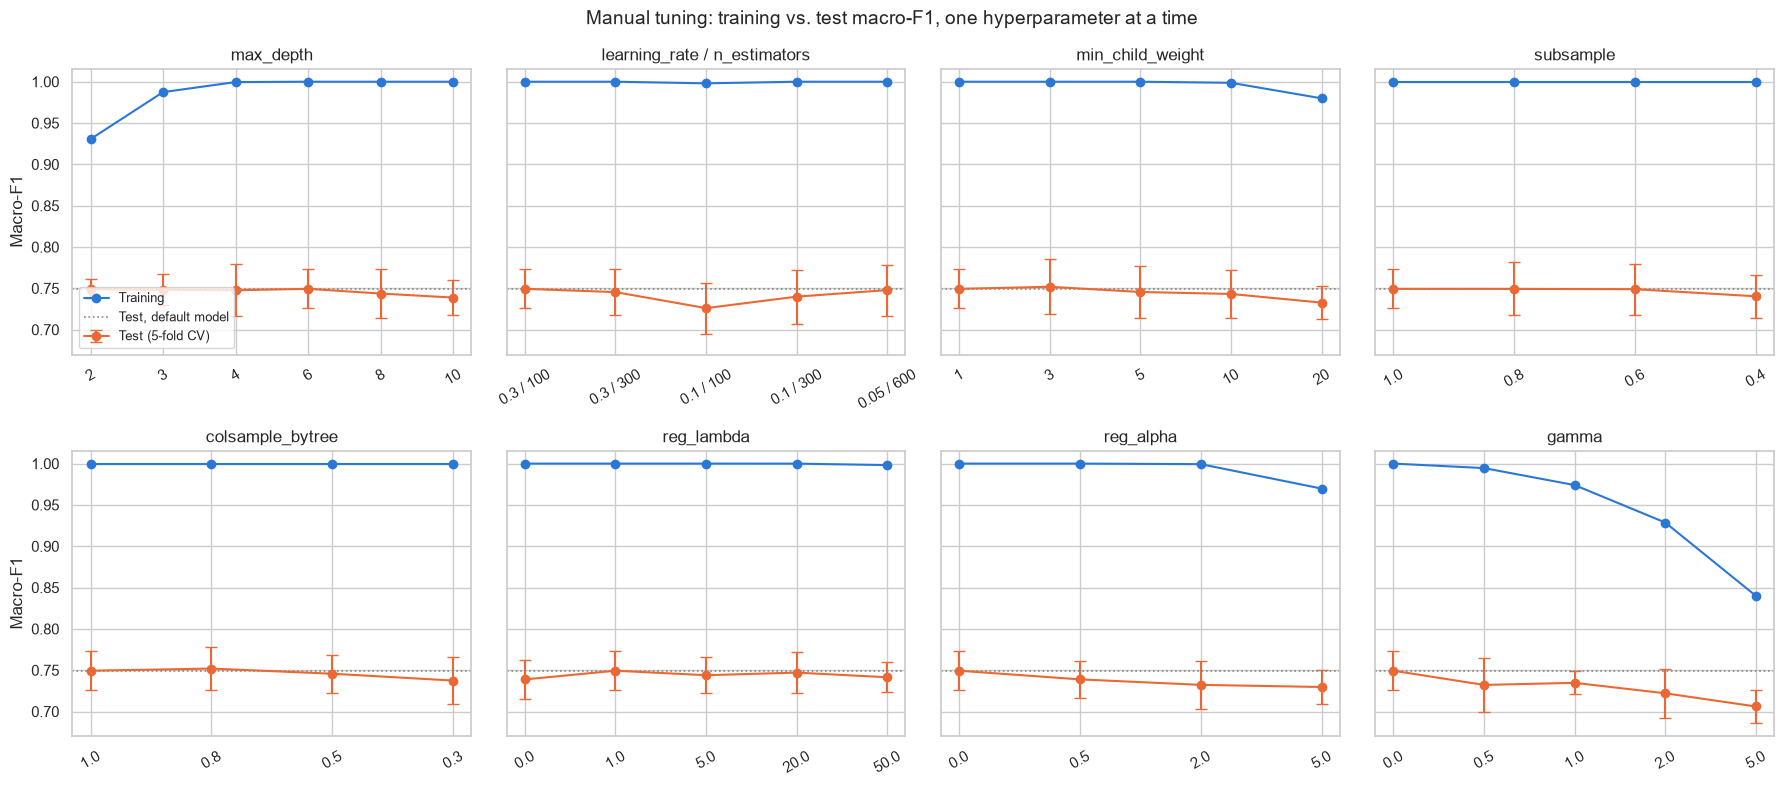

In [9]:
SWEEPS = {
    "max_depth": sweep_depth,
    "learning_rate / n_estimators": sweep_rate,
    "min_child_weight": sweep_mcw,
    "subsample": sweep_subsample,
    "colsample_bytree": sweep_colsample,
    "reg_lambda": sweep_lambda,
    "reg_alpha": sweep_alpha,
    "gamma": sweep_gamma,
}


def value_labels(df):
    """Axis labels of a sweep, e.g. "0.1 / 300" for learning_rate / n_estimators."""
    params = [col for col in df.columns if col not in METRICS]
    return df[params].astype(str).agg(" / ".join, axis=1)


fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
for ax, (name, df) in zip(axes.flat, SWEEPS.items()):
    labels = value_labels(df)
    ax.plot(labels, df["Train Macro-F1"], marker="o", color="#2a78d6", label="Training")
    ax.errorbar(labels, df["Test Macro-F1"], yerr=df["Test Macro-F1 Std"], marker="o", capsize=4,
                color="#eb6834", label="Test (5-fold CV)")
    ax.axhline(baseline_scores["Test Macro-F1"], color="#898781", linestyle=":", linewidth=1.2,
               label="Test, default model")
    ax.set_title(name, fontsize=12)
    ax.tick_params(axis="x", rotation=30)
for ax in axes[:, 0]:
    ax.set_ylabel("Macro-F1")
axes[0, 0].legend(loc="lower left", fontsize=9)
fig.suptitle("Manual tuning: training vs. test macro-F1, one hyperparameter at a time", fontsize=14)
plt.tight_layout()
plt.show()

#### Interpretation of the manual experiments
* **Training score:** only four hyperparameters push the training macro-F1 clearly below 1.0: `max_depth` (0.9305 at 2), `gamma` (0.8400 at 5), `reg_alpha` (0.9697 at 5) and `min_child_weight` (0.9799 at 20). The learning rate, the two sampling rates and `reg_lambda` leave it at 0.998 or above. The default model memorizes the training houses so easily that changing one of these alone does not stop it.
* **Test score:** no single change improves the test macro-F1 by more than 0.003 (`min_child_weight` 3: +0.0025, `colsample_bytree` 0.8: +0.0026). That is far within the spread over the folds (about ± 0.02–0.03). Every change that lowers the training score either lowers the test score as well, or leaves it unchanged (`max_depth` 2–4).
* **Bias-variance:** along each single hyperparameter, the default lies at or close to the best point. Reducing the variance with one hyperparameter adds about as much bias as it removes, so the gap of about 0.25 cannot be closed by changing one hyperparameter alone.

#### 1.8 Combining the best values
Taking the best value of every experiment and combining them is the natural next step of manual tuning. It is not guaranteed to work: each value was chosen with all other hyperparameters at their default, but the hyperparameters interact (e.g. a smaller learning rate needs more rounds, deeper trees need more regularization).

In [10]:
# Best test macro-F1 of every experiment; if the default value wins, the default stays
manual_params = {}
for df in SWEEPS.values():
    best = df.loc[df["Test Macro-F1"].idxmax()]
    manual_params.update({col: best[col] for col in df.columns if col not in METRICS})
# Integer hyperparameters come back as floats from the data frame
manual_params = {k: int(v) if k in ("max_depth", "n_estimators") else float(v) for k, v in manual_params.items()}
changed = {k: v for k, v in manual_params.items() if v != DEFAULTS[k]}
print("Changed against the defaults:", changed)

manual_scores = cv_scores(make_model(**manual_params))
display(pd.DataFrame(
    [baseline_scores, manual_scores], index=["Default hyperparameters", "Manual combination"]
).round(4))

Changed against the defaults: {'min_child_weight': 3.0, 'colsample_bytree': 0.8}


,Train Macro-F1,Test Macro-F1,Test Macro-F1 Std,Test Accuracy,Gap
Default hyperparameters,1.0,0.7494,0.0236,0.7641,0.2506
Manual combination,1.0,0.7470,0.0334,0.7624,0.2530


* The two values that beat the default, `min_child_weight` = 3 and `colsample_bytree` = 0.8, reach only 0.7470 ± 0.0334 together. That is lower than either of them alone (0.7519, 0.7520) and lower than the default (0.7494). The training macro-F1 stays 1.0.
* Both single gains (+0.0025, +0.0026) were smaller than the noise, so they were partly lucky results on these 5 folds, and such gains do not add up. On top of that, the hyperparameters interact: the best value of one depends on the values of the others.
* Manual tuning one parameter at a time therefore does not find a better model. That needs a joint search over all hyperparameters, which is the job of the Bayesian optimization in Section 2.

### 2. Bayesian optimization with Optuna (`TPESampler`)

**How TPE works.** Bayesian optimization uses the results of the previous trials to decide which hyperparameters to try next. The Tree-structured Parzen Estimator (TPE) splits the finished trials into the best ones (a share $\gamma$) and the rest, and estimates two densities over the hyperparameters with Parzen (kernel density) estimators: $l(x)$ from the good trials and $g(x)$ from the others. The next trial is the candidate $x$ with the highest ratio $l(x)/g(x)$, which is equivalent to maximizing the expected improvement. Before that, the first `n_startup_trials = 10` trials are drawn at random to get a first picture of the search space.

**Setup:**
* **Objective:** the mean macro-F1 over the same 5 stratified folds as in Section 1.
* **Search space:** all nine hyperparameters of Section 1 at once, with ranges that contain the values tried manually and extend beyond them. Parameters that span several orders of magnitude (`learning_rate`, `min_child_weight`, `reg_lambda`, `reg_alpha`) are searched on a log scale.
* **Pruning:** after every fold, the trial reports the mean macro-F1 of the folds so far. The `MedianPruner` stops a trial after its second fold or later if this value is below the median of the earlier trials at the same fold, which saves time on clearly bad configurations.
* **Intermediate steps:** every trial is saved in the SQLite database `optuna_ames_housing.db` as soon as it finishes. When the notebook is run again, the study is loaded and only the missing trials are run, so an interrupted search continues where it stopped. (The database also contains an earlier study, `ames_xgboost_macro_f1`, run on a different data setup with 2,930 houses and 79 features; it is not used here.)

In [11]:
STORAGE = "sqlite:///optuna_ames_housing.db"
STUDY_NAME = "xgboost_macro_f1_tpe"
N_TRIALS = 100


def objective(trial):
    """Mean macro-F1 over the 5 stratified folds for one hyperparameter combination."""
    params = {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 30.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.4, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100.0, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 0.001, 10.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
    }
    model = make_model(**params)

    fold_scores = []
    for step, split in enumerate(cv5):
        fitted = clone(model).fit(X.loc[split["train"]], y.loc[split["train"]])
        fold_scores.append(f1_score(y.loc[split["test"]], fitted.predict(X.loc[split["test"]]), average="macro"))
        # Running mean after each fold, so the pruner can stop clearly bad trials early
        trial.report(np.mean(fold_scores), step)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return np.mean(fold_scores)


def print_progress(study, trial):
    """Short status line after every 10 trials."""
    if (trial.number + 1) % 10 == 0:
        print(f"{trial.number + 1:>3} trials: best macro-F1 {study.best_value:.4f} (trial {study.best_trial.number})")


study = optuna.create_study(
    study_name=STUDY_NAME,
    storage=STORAGE,
    load_if_exists=True,
    direction="maximize",
    sampler=TPESampler(n_startup_trials=10, seed=42),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=1),
)

# Resume: only the trials that are not yet stored in the database are run
remaining = N_TRIALS - len(study.trials)
print(f"{len(study.trials)} trials already stored, running {max(remaining, 0)} more.")
if remaining > 0:
    study.optimize(objective, n_trials=remaining, callbacks=[print_progress])

trials = study.trials_dataframe()
print("\nTrial states:", trials["state"].value_counts().to_dict())
print(f"Best trial: #{study.best_trial.number} with mean macro-F1 {study.best_value:.4f}")

# The 10 best finished trials, with their hyperparameters
top = trials[trials["state"] == "COMPLETE"].sort_values("value", ascending=False).head(10)
top = top[["number", "value"] + [col for col in trials if col.startswith("params_")]]
display(top.rename(columns=lambda col: col.removeprefix("params_")).set_index("number").round(4))

0 trials already stored, running 100 more.


 10 trials: best macro-F1 0.7415 (trial 2)


 20 trials: best macro-F1 0.7504 (trial 17)


 30 trials: best macro-F1 0.7504 (trial 17)


 40 trials: best macro-F1 0.7521 (trial 31)


...

 70 trials: best macro-F1 0.7556 (trial 53)


 80 trials: best macro-F1 0.7556 (trial 53)


 90 trials: best macro-F1 0.7556 (trial 53)


100 trials: best macro-F1 0.7556 (trial 53)

Trial states: {'COMPLETE': 89, 'PRUNED': 11}
Best trial: #53 with mean macro-F1 0.7556


,value,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,subsample
number,,,,,,,,,,
53,0.7556,0.5028,0.6809,0.0533,4,1.8677,800,0.0054,0.5747,0.6418
80,0.7545,0.5961,0.3924,0.0270,5,2.5824,700,0.0026,0.2431,0.7619
73,0.7540,0.5490,0.1408,0.0336,5,2.1595,700,0.0034,0.0449,0.6521
85,0.7540,0.4564,0.3264,0.0412,5,2.6452,700,0.0037,0.2341,0.6548
86,0.7540,0.5287,0.0474,0.0339,5,1.9312,700,0.0025,0.1540,0.6391
93,0.7538,0.4600,0.3083,0.0482,5,2.1443,750,0.0049,0.1513,0.6184
42,0.7537,0.5238,0.6656,0.0440,4,2.2083,800,0.0120,0.0322,0.6385
60,0.7536,0.4666,0.6922,0.0562,5,2.1647,850,0.0111,0.2480,0.5820
88,0.7536,0.5034,0.5890,0.0361,4,2.0410,800,0.0027,0.1532,0.6319


#### Interpretation of the search result
* **Best trial:** #53, with a mean macro-F1 of 0.7556 on the 5 folds. That is +0.0062 over the default (0.7494) and better than every manual configuration (best: 0.7520). 89 trials finished, and 11 were stopped by the pruner.
* **Best hyperparameters:** `max_depth` 4, `learning_rate` 0.0533 with 800 rounds, `subsample` 0.642, `colsample_bytree` 0.503, `min_child_weight` 1.87, `gamma` 0.681, `reg_lambda` 0.575 and `reg_alpha` 0.0054.
* **The 10 best trials agree:**
  * depth 4–5
  * learning rate 0.027–0.056 with 700–850 rounds
  * `subsample` 0.58–0.76 and `colsample_bytree` 0.46–0.60
  * `min_child_weight` 1.87–2.65 and `gamma` 0.05–0.69
  * `reg_lambda` 0.03–0.57 and `reg_alpha` 0.0025–0.012, which means practically no L1 penalty

  Their scores lie within 0.0021 of each other (0.7535–0.7556).
* **Why this works where the manual search did not:** the good region combines several moderate regularizations at once: a small learning rate with many rounds, about 60% of the houses and 50% of the features per tree, slightly shallower trees and a small $\gamma$. In the manual experiments, each of the first three alone gave nothing (0.05 / 600: 0.7479, `subsample` 0.6: 0.7489, `colsample_bytree` 0.5: 0.7458). Together they make up stochastic gradient boosting with shrinkage: every tree sees different houses and features, and the small learning rate averages over many such randomized trees, similar to a random forest. This lowers the variance without the large bias of strong single regularizations such as a large $\gamma$.
* **The gain is small:** +0.0062 is smaller than the standard deviation over the 5 folds. It is also the best of 100 tries on the same folds, so it is partly selection luck. Section 4 checks it on other splits.

### 3. Visualizations of the optimization process

**How the search progressed:**
* **Optimization history:** the macro-F1 of every finished trial and the best value found so far.
* **Intermediate values:** the running mean macro-F1 after each fold for every trial; the lines that end early are pruned trials.

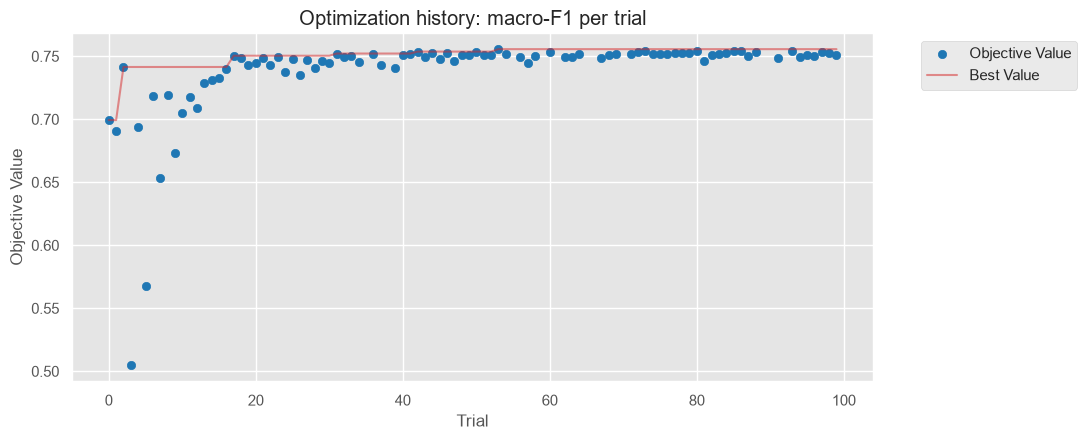

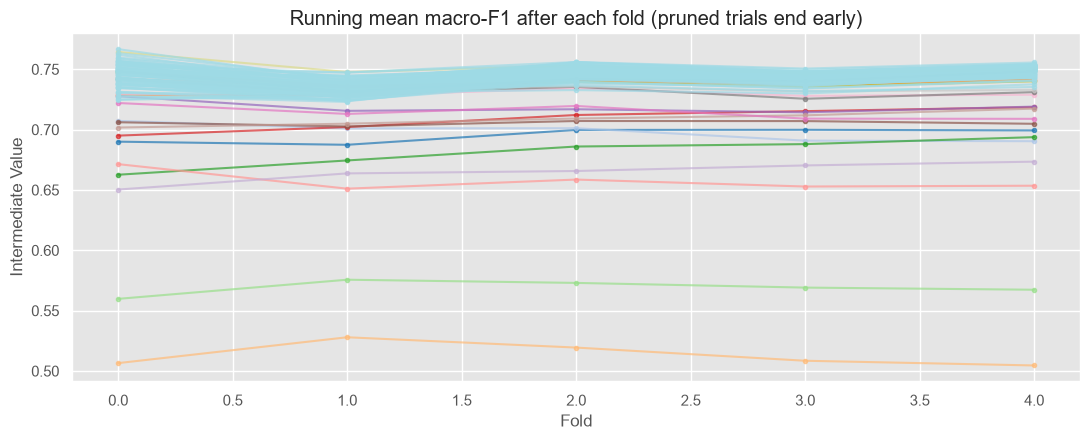

In [12]:
ax = optuna_plots.plot_optimization_history(study)
ax.figure.set_size_inches(11, 4.5)
ax.set_title("Optimization history: macro-F1 per trial")
plt.show()

ax = optuna_plots.plot_intermediate_values(study)
ax.figure.set_size_inches(11, 4.5)
ax.set_title("Running mean macro-F1 after each fold (pruned trials end early)")
ax.set_xlabel("Fold")
if ax.get_legend() is not None:
    ax.get_legend().remove()  # one entry per trial, too many to read
plt.show()

#### Interpretation of the search progress
* **Random start:** the 10 startup trials are drawn at random and spread widely, from about 0.50 to 0.7415 (trial 2, the best of them).
* **TPE phase:** from trial 10 on, TPE samples where the good trials lie, and almost all later trials lie in a narrow band just below the best value. The best value improves in small steps: 0.7504 (trial 17), 0.7521 (trial 31), 0.7537 (trial 42) and 0.7556 (trial 53), and then not at all in the last 47 trials. The search has converged: more trials would at most bring gains far below the noise between folds.
* **Intermediate values:** the running means of almost all trials move up and down together from fold to fold, e.g. lower at fold 1. Some folds are harder than others for every model. Because the pruner compares a trial only with other trials at the same fold, this does not distort it.
* **Search space:** the slice plot shows no trial with `max_depth` 7 or 8. None of the random startup trials drew these values, and TPE then concentrated on depths 4 and 5. Section 1.1 already showed that depths 8 and 10 are worse, so this costs little.

**Which hyperparameters mattered:**
* **Hyperparameter importance:** estimated with fANOVA, which fits a random forest from the hyperparameters to the macro-F1 of the finished trials and measures how much of the variation in macro-F1 each hyperparameter explains.
* **Slice plots:** the macro-F1 of every trial against each hyperparameter; the color shows the trial number, so later trials (where TPE has learned more) are darker.
* **Parallel coordinates:** every line is one trial through all hyperparameters, colored by its macro-F1.
* **Contour plot:** the macro-F1 over the two most important hyperparameters.

Hyperparameter importance (fANOVA):
reg_alpha           0.484
reg_lambda          0.226
gamma               0.094
colsample_bytree    0.052
n_estimators        0.040
subsample           0.037
max_depth           0.034
min_child_weight    0.032
learning_rate       0.000


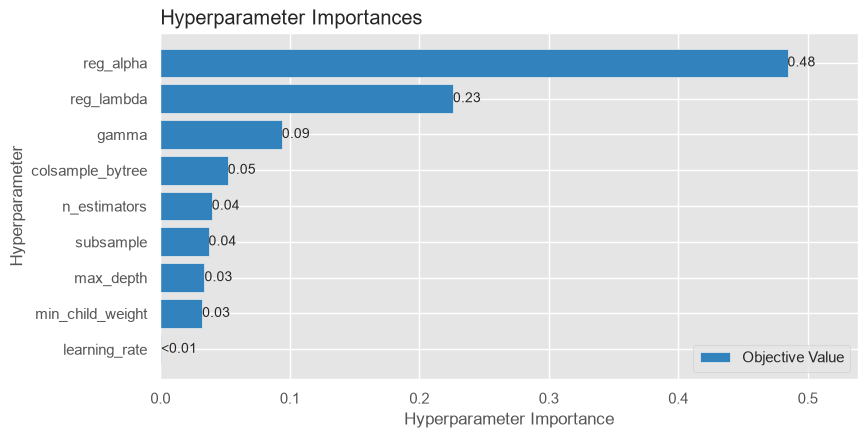

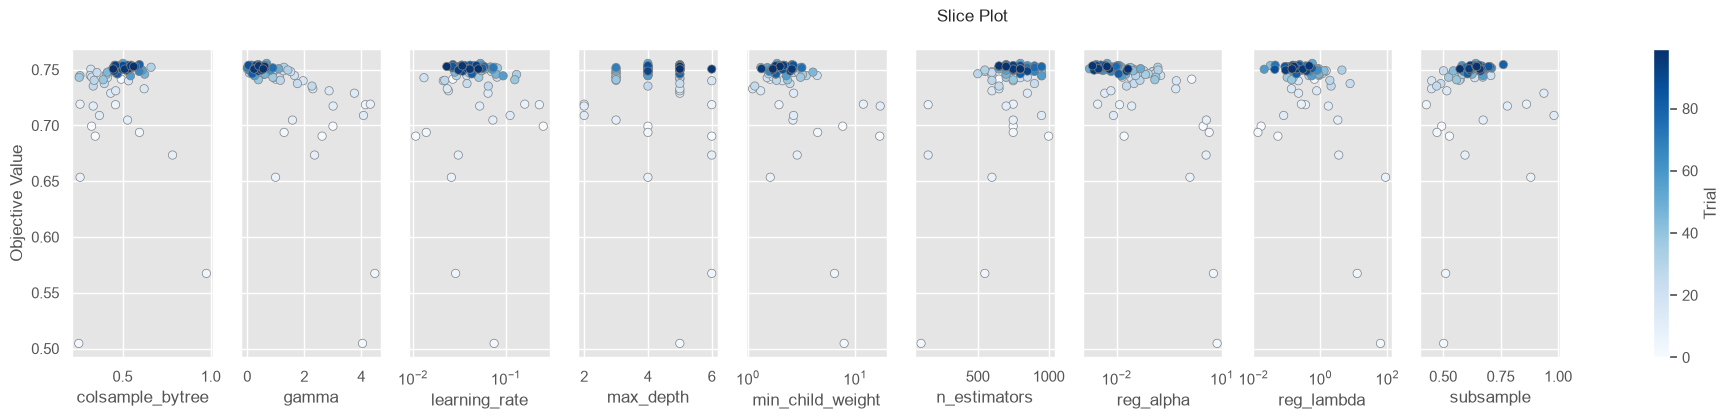

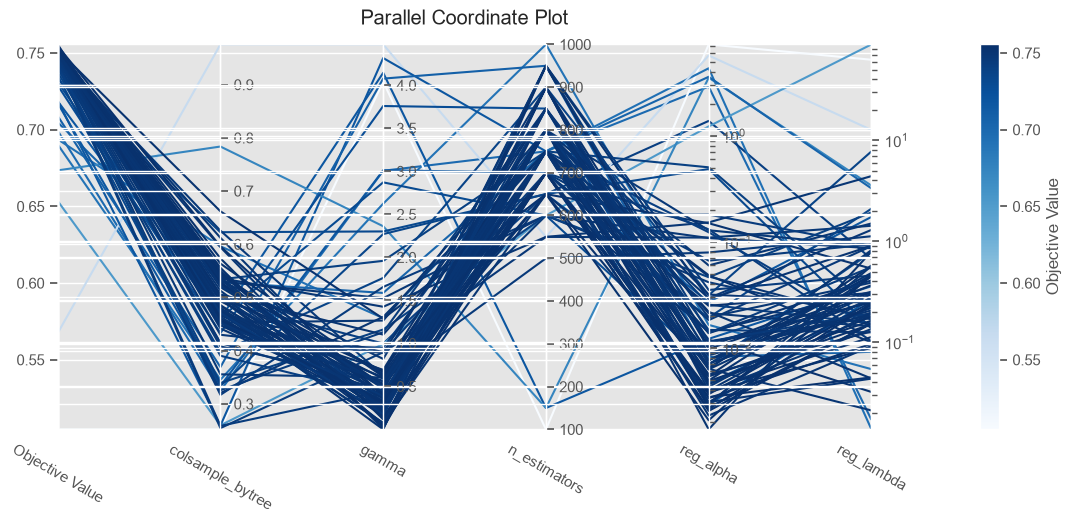

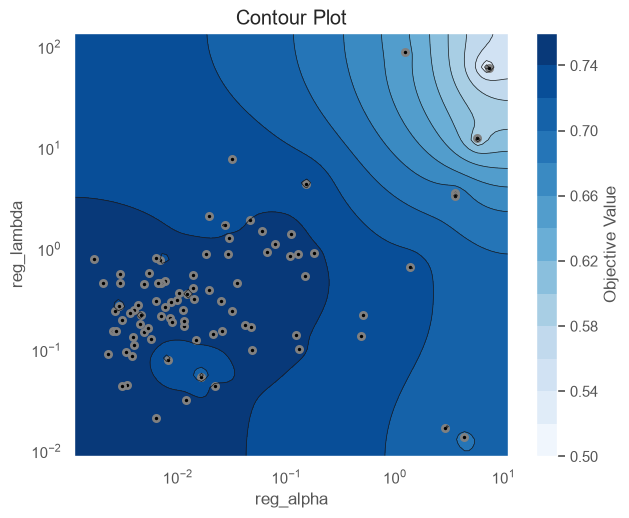

In [13]:
# Fixed seed so that the fANOVA importances are reproducible
evaluator = optuna.importance.FanovaImportanceEvaluator(seed=42)
importances = optuna.importance.get_param_importances(study, evaluator=evaluator)
print("Hyperparameter importance (fANOVA):")
print(pd.Series(importances).round(3).to_string())

ax = optuna_plots.plot_param_importances(study, evaluator=evaluator)
ax.figure.set_size_inches(9, 4.5)
plt.show()

axes = optuna_plots.plot_slice(study)
axes.flat[0].figure.set_size_inches(24, 4)
plt.show()

# Only the five most important hyperparameters, otherwise the axis labels overlap
ax = optuna_plots.plot_parallel_coordinate(study, params=list(importances)[:5])
ax.figure.set_size_inches(14, 5)
plt.show()

top_two = list(importances)[:2]
ax = optuna_plots.plot_contour(study, params=top_two)
ax.figure.set_size_inches(7, 5.5)
plt.show()

#### Interpretation of the hyperparameter importance
* **Importance:** fANOVA attributes most of the variation in macro-F1 to `reg_alpha` (0.484) and `reg_lambda` (0.226), followed by `gamma` (0.094). All other hyperparameters have an importance of 0.052 or less, and `learning_rate` 0.000.
* **What this means:** the importance measures how much the macro-F1 changes over the explored values, not which value is best. The slice plots and the contour plot show where it comes from: the trials with large penalties (the right end of the `reg_alpha` and `reg_lambda` slices) are by far the worst, down to about 0.50, and almost all of them come from the random startup phase. Once the penalties are small, they hardly matter, and the darkest region of the contour plot lies at small values of both. In the best trials `reg_alpha` is practically 0, consistent with Section 1.5, where every L1 penalty hurt. So the importance says "avoid large penalties", not "tune them finely".
* **`learning_rate` with importance 0.000:** this does not mean the learning rate is irrelevant (Section 1.2 shows the opposite). TPE quickly concentrated it in a narrow good range (0.027–0.056 in the 10 best trials), and the bad trials are explained by other hyperparameters. Importance estimates from the trials of a guided search only describe the region that was actually explored.
* **Parallel coordinates:** the dark lines (high macro-F1) run through small values of `colsample_bytree`, `gamma`, `reg_alpha` and `reg_lambda` and through high numbers of rounds, which is the same region as the 10 best trials.

### 4. Final model

`study.best_value` is optimistic: out of 100 trials, the best one is partly the best because it happened to fit these 5 folds well (selection bias), just like the best value of each manual experiment. The tuned models are therefore evaluated again on all 70 splits of notebooks 02 and 04 (holdout 10% / 20% and CV $k$ = 5 / 10, each with and without stratification). Only "CV k=5, stratified" was used for tuning, so the other 65 splits are a fairer test, although they still contain the same houses.

Compared are the baseline (default hyperparameters), the manual combination of Section 1.8 and the best Optuna trial, all fitted and scored on the same splits.

In [14]:
best_params = study.best_params
MODELS = {
    "Baseline (defaults)": make_model(),
    "Manual combination": make_model(**manual_params),
    "Optuna best trial": make_model(**best_params),
}

final_results = pd.concat(
    [evaluate(model, X, y, splits).assign(Variant=name) for name, model in MODELS.items()], ignore_index=True
)

print("Test macro-F1, mean ± std over the splits of each setup")
display(summarize(final_results, "Test Macro-F1"))
print("Test accuracy, mean ± std over the splits of each setup")
display(summarize(final_results, "Test Accuracy"))

# Bias-variance: training vs. test macro-F1, averaged over all 70 splits
gap = final_results.groupby("Variant", sort=False)[["Train Macro-F1", "Test Macro-F1"]].mean()
gap["Gap"] = gap["Train Macro-F1"] - gap["Test Macro-F1"]
print("Training vs. test macro-F1 over all 70 splits")
display(gap.round(4))

# Paired differences to the baseline on the same split (positive = better than the baseline)
differences = paired_differences(final_results, "Baseline (defaults)")
experiment = differences.index.get_level_values("Setup").str.split().str[0]
print("Macro-F1 minus the baseline's macro-F1 on the same split")
display(pd.concat({
    name: pd.DataFrame({
        "Mean Difference": group.mean(),
        "Std": group.std(),
        "Better": (group > 0).sum(),
        "Worse": (group < 0).sum(),
    })
    for name, group in [*differences.groupby(experiment, sort=False), ("All 70 splits", differences)]
}, axis=1).round(4))

Test macro-F1, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
Baseline (defaults),0.7486 ± 0.0238,0.7596 ± 0.0342,0.7357 ± 0.0172,0.7546 ± 0.0245,0.7421 ± 0.0286,0.7494 ± 0.0236,0.7574 ± 0.0252,0.7546 ± 0.0432
Manual combination,0.7518 ± 0.0225,0.7657 ± 0.0448,0.7367 ± 0.0200,0.7568 ± 0.0200,0.7386 ± 0.0265,0.7470 ± 0.0334,0.7489 ± 0.0265,0.7484 ± 0.0375
Optuna best trial,0.7595 ± 0.0290,0.7699 ± 0.0381,0.7563 ± 0.0145,0.7656 ± 0.0198,0.7549 ± 0.0190,0.7556 ± 0.0187,0.7516 ± 0.0212,0.7502 ± 0.0481


Test accuracy, mean ± std over the splits of each setup


Setup,Holdout 10%,"Holdout 10%, stratified",Holdout 20%,"Holdout 20%, stratified",CV k=5,"CV k=5, stratified",CV k=10,"CV k=10, stratified"
Variant,,,,,,,,
Baseline (defaults),0.7546 ± 0.0198,0.7689 ± 0.0311,0.7547 ± 0.0121,0.7615 ± 0.0176,0.7542 ± 0.0235,0.7641 ± 0.0215,0.7648 ± 0.0212,0.7665 ± 0.0329
Manual combination,0.7631 ± 0.0169,0.7706 ± 0.0225,0.7521 ± 0.0128,0.7668 ± 0.0151,0.7556 ± 0.0148,0.7624 ± 0.0212,0.7614 ± 0.0229,0.7655 ± 0.0295
Optuna best trial,0.7683 ± 0.0226,0.7799 ± 0.0260,0.7704 ± 0.0118,0.7759 ± 0.0077,0.7648 ± 0.0150,0.7768 ± 0.0202,0.7685 ± 0.0199,0.7716 ± 0.0312


Training vs. test macro-F1 over all 70 splits


,Train Macro-F1,Test Macro-F1,Gap
Variant,,,
Baseline (defaults),1.0000,0.7509,0.2491
Manual combination,1.0000,0.7502,0.2498
Optuna best trial,0.9883,0.7583,0.2300


Macro-F1 minus the baseline's macro-F1 on the same split


Holdout                                   CV  \
                   Mean Difference     Std Better Worse Mean Difference   
Variant                                                                   
Manual combination          0.0031  0.0187     25    15         -0.0059   
Optuna best trial           0.0132  0.0199     31     9         -0.0002   

                                          All 70 splits                       
                       Std Better Worse Mean Difference     Std Better Worse  
Variant                                                                       
Manual combination  0.0261     13    17         -0.0007  0.0224     38    32  
Optuna best trial   0.0247     16    14          0.0074  0.0229     47    23

#### Interpretation of the final comparison
* **Optuna best trial vs. baseline:** the test macro-F1 is higher in 6 of the 8 setups, by 0.006–0.021 (most for the 20% holdout: 0.7563 vs. 0.7357), but lower with 10-fold cross-validation (0.7516 vs. 0.7574 and 0.7502 vs. 0.7546). The accuracy is higher in all 8 setups, by 0.004–0.016.
* **Paired differences:** over all 70 splits, the tuned model is better by 0.0074 on average and wins on 47 of them. The gain comes from the holdout splits (+0.0132, better on 31 of 40). On the 30 cross-validation folds, including the 5 tuning folds, it is zero (−0.0002, better on 16, worse on 14).
* **Bias-variance:** the training macro-F1 drops from 1.0 to 0.9883 while the test macro-F1 rises from 0.7509 to 0.7583, so the gap shrinks from 0.2491 to 0.2300. This is the only configuration in this notebook that lowers the training score *and* raises the test score: it reduces the variance without adding as much bias. The gap is still large, though. In notebook 03, 97% of the errors were houses in an adjacent price class, and regularization cannot make the features separate such houses better.
* **Manual combination:** practically equal to the baseline (−0.0007, better on 38 of 70), as already seen in Section 1.8.
* **How certain is the gain:** +0.0074 macro-F1 is smaller than the standard deviation of the paired differences (0.0229), and the 10-fold cross-validation does not confirm it. The tuned model is probably slightly better (its accuracy rises in every setup), but its macro-F1 gain is about as large as the noise of a single evaluation.

#### 4.1 Diagnostics of the tuned model
The metrics of notebook 03, now for the best Optuna trial and the baseline side by side: pooled out-of-fold predictions of the 5 stratified folds, per-class precision, recall and F1, and the confusion matrix. Finally, the nested threshold check of notebook 03, Section 5 (same procedure): do per-class thresholds help the tuned model?

Pooled out-of-fold metrics


,Accuracy,Macro Precision,Macro Recall,Macro F1
Model,,,,
Baseline (defaults),0.7641,0.7806,0.7298,0.7518
Optuna best trial,0.7768,0.7885,0.7368,0.7592


Precision, recall and F1 per class


Baseline (defaults)                 Optuna best trial          \
                    Precision  Recall      F1         Precision  Recall   
< 100k                 0.7716  0.6414  0.7005            0.7822  0.6667   
100k–130k              0.6770  0.6424  0.6593            0.6936  0.6582   
130k–180k              0.7743  0.8311  0.8017            0.7794  0.8456   
180k–250k              0.7688  0.7778  0.7733            0.7935  0.7865   
250k–400k              0.8168  0.8086  0.8127            0.8312  0.8186   
≥ 400k                 0.8750  0.6774  0.7636            0.8511  0.6452   

                   
               F1  
< 100k     0.7198  
100k–130k  0.6754  
130k–180k  0.8111  
180k–250k  0.7900  
250k–400k  0.8249  
≥ 400k     0.7339

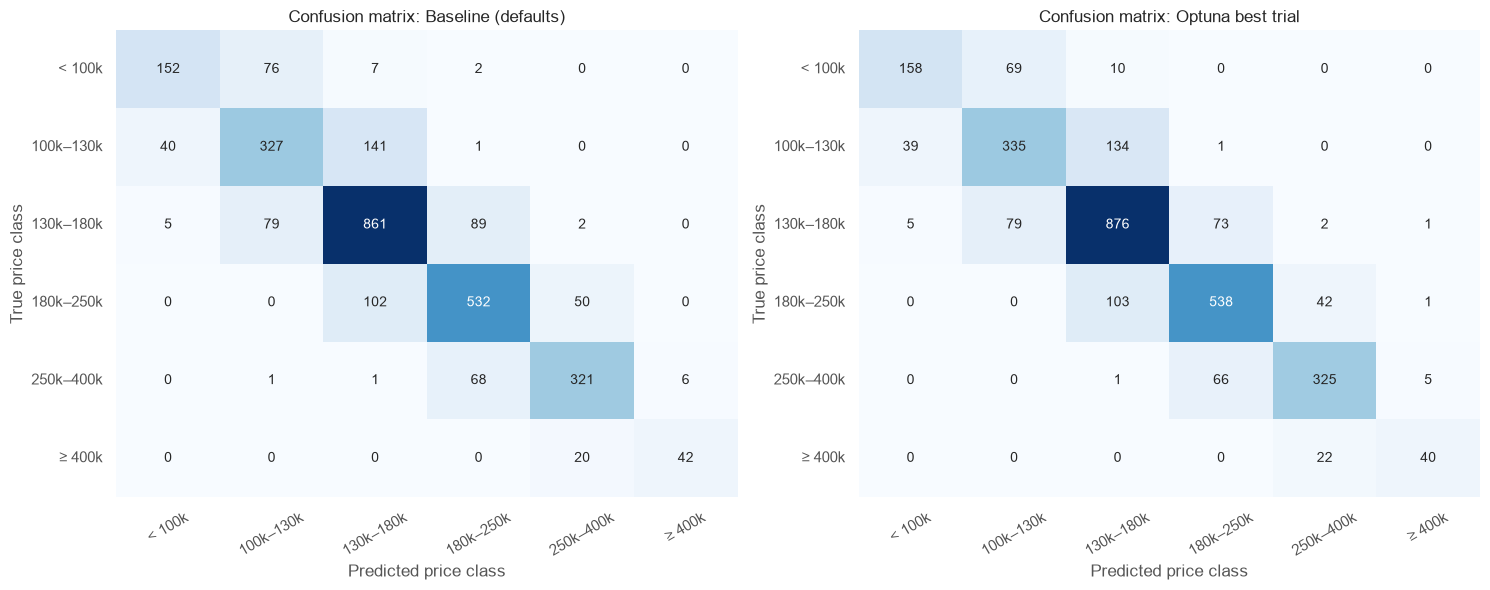

Optuna best trial: 653 misclassified houses, 632 of them (96.8%) in an adjacent class



Optuna best trial: default argmax vs. joint search thresholds (nested)


,Accuracy,Macro F1
Decision rule,,
Default argmax,0.7768,0.7592
Joint search thresholds (nested),0.7709,0.7561


In [15]:
def out_of_fold_proba(model):
    """Out-of-fold class probabilities on the 5 stratified folds."""
    proba = np.zeros((len(y), len(CLASS_NAMES)))
    for split in cv5:
        fitted = clone(model).fit(X.loc[split["train"]], y.loc[split["train"]])
        proba[y.index.get_indexer(split["test"])] = fitted.predict_proba(X.loc[split["test"]])
    return proba


y_arr = y.to_numpy()
oof = {name: out_of_fold_proba(MODELS[name]) for name in ["Baseline (defaults)", "Optuna best trial"]}
oof_pred = {name: proba.argmax(axis=1) for name, proba in oof.items()}

print("Pooled out-of-fold metrics")
display(pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_arr, pred),
        "Macro Precision": precision_score(y_arr, pred, average="macro"),
        "Macro Recall": recall_score(y_arr, pred, average="macro"),
        "Macro F1": f1_score(y_arr, pred, average="macro"),
    }
    for name, pred in oof_pred.items()
]).set_index("Model").round(4))

print("Precision, recall and F1 per class")
display(pd.concat({
    name: pd.DataFrame({
        "Precision": precision_score(y_arr, pred, average=None),
        "Recall": recall_score(y_arr, pred, average=None),
        "F1": f1_score(y_arr, pred, average=None),
    }, index=CLASS_NAMES)
    for name, pred in oof_pred.items()
}, axis=1).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, pred) in zip(axes, oof_pred.items()):
    sns.heatmap(confusion_matrix(y_arr, pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f"Confusion matrix: {name}", fontsize=12)
    ax.set_xlabel("Predicted price class")
    ax.set_ylabel("True price class")
    ax.tick_params(axis="x", rotation=30)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

tuned_pred = oof_pred["Optuna best trial"]
off_by_one = (np.abs(y_arr - tuned_pred) == 1).sum()
errors = (y_arr != tuned_pred).sum()
print(f"Optuna best trial: {errors} misclassified houses, {off_by_one} of them ({off_by_one / errors:.1%}) in an adjacent class")


# Nested threshold check, same procedure as notebook 03, Section 5
GRID = np.linspace(0.05, 0.70, 66)


def pr_curve_thresholds(P, y_true):
    """Per class: the threshold with the best one-vs-rest F1 on its precision-recall curve."""
    taus = []
    for c in range(len(CLASS_NAMES)):
        prec, rec, thresh = precision_recall_curve(y_true == c, P[:, c])
        prec, rec = prec[:-1], rec[:-1]
        f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros_like(prec), where=(prec + rec) > 0)
        taus.append(thresh[np.argmax(f1)])
    return np.array(taus)


def predict_with_thresholds(P, taus):
    """Class with the highest probability relative to its threshold."""
    return (P / taus).argmax(axis=1)


def joint_search(P, y_true, taus, passes=3):
    """Coordinate search: set one threshold at a time to the grid value with the best macro-F1."""
    taus = taus.copy()
    best = f1_score(y_true, predict_with_thresholds(P, taus), average="macro")
    for _ in range(passes):
        for c in range(len(CLASS_NAMES)):
            for candidate in GRID:
                trial_taus = taus.copy()
                trial_taus[c] = candidate
                score = f1_score(y_true, predict_with_thresholds(P, trial_taus), average="macro")
                if score > best:
                    best, taus = score, trial_taus
    return taus


P = oof["Optuna best trial"]
pred_nested = np.zeros(len(y_arr), dtype=int)
for train_idx, val_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(P, y_arr):
    taus = joint_search(P[train_idx], y_arr[train_idx], pr_curve_thresholds(P[train_idx], y_arr[train_idx]))
    pred_nested[val_idx] = predict_with_thresholds(P[val_idx], taus)

print("\nOptuna best trial: default argmax vs. joint search thresholds (nested)")
display(pd.DataFrame([
    {"Decision rule": name, "Accuracy": accuracy_score(y_arr, pred), "Macro F1": f1_score(y_arr, pred, average="macro")}
    for name, pred in [("Default argmax", tuned_pred), ("Joint search thresholds (nested)", pred_nested)]
]).set_index("Decision rule").round(4))

#### Interpretation of the diagnostics
* **Pooled out-of-fold:**
  * The accuracy rises from 0.7641 to 0.7768 and the macro-F1 from 0.7518 to 0.7592. Both the macro precision (0.7806 → 0.7885) and the macro recall (0.7298 → 0.7368) rise.
  * 653 houses are misclassified (690 for the baseline in notebook 03), and 96.8% of them fall into an adjacent class.
* **Per class:** the F1 rises for the five larger classes, by 0.009 (`130k–180k`) to 0.019 (`< 100k`). It falls for `≥ 400k`, from 0.7636 to 0.7339: its recall drops from 0.6774 to 0.6452 (40 instead of 42 of the 62 houses), and its precision from 0.875 to 0.851.
* **Why the rarest class loses:** the regularization that helps the other classes hits the class with the fewest training houses (about 50 per fold) hardest. Every tree sees only about 64% of the houses and 50% of the features, and $\gamma$ removes weak splits. The patterns of this class rest on few houses, so they are more often missing from a tree's sample, or they only produce weak splits. Notebook 04 (Section 5) tested SMOTE and class weights for this on the baseline: both find more houses ≥ \$400k but produce more false alarms, so the F1 of this class fell there as well.
* **Thresholds:** as for the baseline in notebook 03, the nested threshold search does not help the tuned model either: the macro-F1 drops from 0.7592 to 0.7561 and the accuracy from 0.7768 to 0.7709. The default argmax stays.

### Conclusion
* **Manual tuning:**
  * No single hyperparameter improves the test macro-F1 by more than 0.003.
  * The ones that reduce the gap (`max_depth`, `gamma`, `reg_alpha`, `min_child_weight`) do so by lowering the training score, while the test score stays the same or falls: less variance, but about as much more bias.
  * Combining the two best single values gave a lower score (0.7470).
* **Bayesian optimization:** within 100 trials, TPE found a region that combines several moderate regularizations: a small learning rate with many rounds, row and column sampling, depth 4–5, a small $\gamma$ and no L1 penalty. It reaches 0.7556 macro-F1 on the tuning folds. The search converged after trial 53, and the key lesson from the importance analysis is to avoid large penalties.
* **Final model:** the best Optuna trial, with
  * `max_depth` = 4, `learning_rate` = 0.0533, `n_estimators` = 800
  * `subsample` = 0.642, `colsample_bytree` = 0.503
  * `min_child_weight` = 1.87, `gamma` = 0.681, `reg_lambda` = 0.575, `reg_alpha` = 0.0054

  Over all 70 splits, it reaches a mean test macro-F1 of 0.7583 (baseline 0.7509) and wins on 47 of the 70 splits. Its accuracy is higher in all 8 setups, and its gap is smaller (0.2300 vs. 0.2491). The gain is small, about as large as the noise between splits, and the 10-fold cross-validation does not confirm it.
* **Remaining weaknesses:** the gap of 0.23 remains, the rarest class `≥ 400k` gets worse (F1 0.7636 → 0.7339), and per-class thresholds do not help. Most errors (96.8%) are houses next to a class boundary, which no hyperparameter setting has separated better so far.